# Stereo vision: SIFT, local patch refinement and triangulation

**Actual photographs:** IMG_0690.jpg and IMG_0692.jpg, iPhone XR. **Assumed lens separation:** 20.1 cm. **Measured front-surface depth:** 28 cm, evaluation only.

Pipeline: SIFT → mutual descriptor matches → local Lucas–Kanade patch refinement → forward/backward consistency → essential-matrix RANSAC → pose recovery → triangulation.

The original raw-disparity estimate remains as the baseline. Triangulation estimates pose internally because these are unrectified handheld images.

**Limitations:** intrinsics from EXIF are approximate; principal point at image centre, square pixels and zero lens distortion are assumed. A change in algorithm is a proposed improvement, not a promised reduction in error.

## 1. Setup
Open in VS Code, select `.venv/Scripts/python.exe`, and Run All. Dependencies: `requirements-notebook.txt`. Keep the original JPEGs in the project root. All calculations use upright full-resolution coordinates; previews are resized only for display. Each run creates a new results folder.


In [6]:
from pathlib import Path
from datetime import datetime
import sys, json, hashlib, platform, csv
import cv2
import numpy as np
from PIL import Image, ImageOps, ImageDraw
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

PROJECT = Path.cwd()
if not (PROJECT / 'IMG_0690.jpg').exists():
    PROJECT = Path(r"D:\Bunker\BaseCamp\ComputerVision\StereoviSON and Depth EstimaSON")
FILES = ['IMG_0690.jpg', 'IMG_0692.jpg']  # presumed left and right camera positions
BASELINE_M = 0.201  # estimated by student; not measured from these photographs
GROUND_TRUTH_M = 0.28  # lens-to-surface measurement for THIS capture only, if available
RATIO = 0.70
VERTICAL_LIMIT_PX = 2.0
RANSAC_PX = 1.5
cv2.setRNGSeed(42)
RUN = PROJECT / 'results' / ('refined_' + datetime.now().strftime('%Y%m%d_%H%M%S_%f'))
RUN.mkdir(parents=True)
print('CPU analysis | Python', platform.python_version(), '| OpenCV', cv2.__version__)
print('Input folder:', PROJECT)
print('Result folder:', RUN)
assert np.isfinite(BASELINE_M) and BASELINE_M > 0


CPU analysis | Python 3.14.0 | OpenCV 4.13.0
Input folder: d:\Bunker\BaseCamp\ComputerVision\StereoviSON and Depth EstimaSON
Result folder: d:\Bunker\BaseCamp\ComputerVision\StereoviSON and Depth EstimaSON\results\refined_20261022_104214_758056


## 2. Original images and camera metadata
EXIF orientation is applied once with Pillow. This matters: the stored JPEG axes are rotated relative to the upright photos. Both images must have the same upright dimensions. No image is cropped, warped or undistorted for this exploratory calculation because distortion calibration is unavailable.

The manually selected rectangles identify the can, keeping wall and table features out of the object distance summary. They do not supply a known can size or distance.


Upright dimensions: 3024 x 4032 pixels
{'file': 'IMG_0690.jpg', 'model': 'iPhone XR', 'orientation': 6, 'focal_mm': 4.25, 'equivalent_focal_mm': 26.0}
{'file': 'IMG_0692.jpg', 'model': 'iPhone XR', 'orientation': 6, 'focal_mm': 4.25, 'equivalent_focal_mm': 26.0}


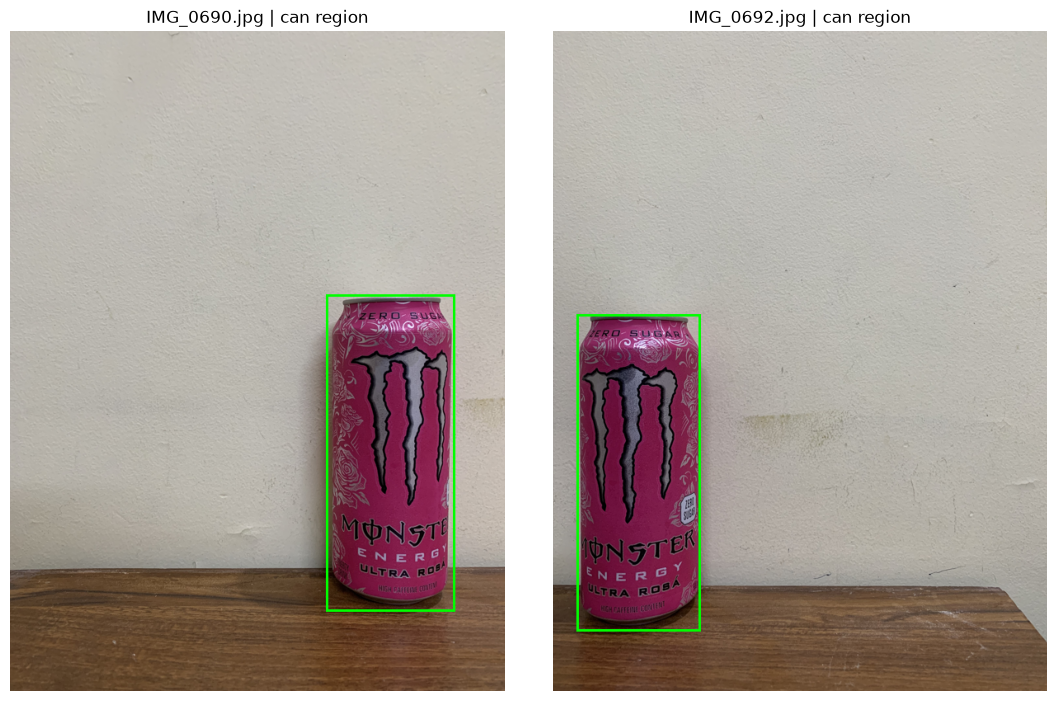

In [7]:
images, metadata = [], []
for filename in FILES:
    with Image.open(PROJECT / filename) as im:
        exif = im.getexif()
        details = exif.get_ifd(34665)
        metadata.append(dict(file=filename, sha256=hashlib.sha256((PROJECT / filename).read_bytes()).hexdigest(),
                             model=str(exif.get(272)), orientation=exif.get(274),
                             focal_mm=float(details.get(37386, 0)),
                             equivalent_focal_mm=float(details.get(41989, 0))))
        images.append(np.array(ImageOps.exif_transpose(im).convert('RGB')))
assert images[0].shape == images[1].shape, 'Different image dimensions'
h, w = images[0].shape[:2]
print('Upright dimensions:', w, 'x', h, 'pixels')
for row in metadata: print({k:v for k,v in row.items() if k != 'sha256'})
# Normalized x0,y0,x1,y1 rectangles, manually selected by viewing these two photographs.
ROIS = [(0.64, 0.40, 0.90, 0.88), (0.05, 0.43, 0.30, 0.91)]
masks = []
fig, axes = plt.subplots(1, 2, figsize=(11, 7))
for ax, rgb, box, name in zip(axes, images, ROIS, FILES):
    x0,y0,x1,y1 = [int(v*s) for v,s in zip(box, [w,h,w,h])]
    mask = np.zeros((h,w), np.uint8); mask[y0:y1,x0:x1] = 255
    masks.append(mask)
    preview = Image.fromarray(rgb).resize((600,800))
    draw = ImageDraw.Draw(preview)
    draw.rectangle((x0*600/w,y0*800/h,x1*600/w,y1*800/h), outline='lime', width=3)
    ax.imshow(preview); ax.set_title(name + ' | can region'); ax.axis('off')
plt.tight_layout(); plt.savefig(RUN/'01_inputs.png', dpi=130); plt.show()


## 3. SIFT: find distinctive points
SIFT detects local image structures at several scales and describes the gradient pattern around each point using a 128 element vector. The labels and patterns on the can provide candidate correspondences. A feature point alone has no depth.

We detect up to 5,000 features per photo within the manually selected can region. Repeated patterns, reflections and viewpoints can still cause incorrect matches.


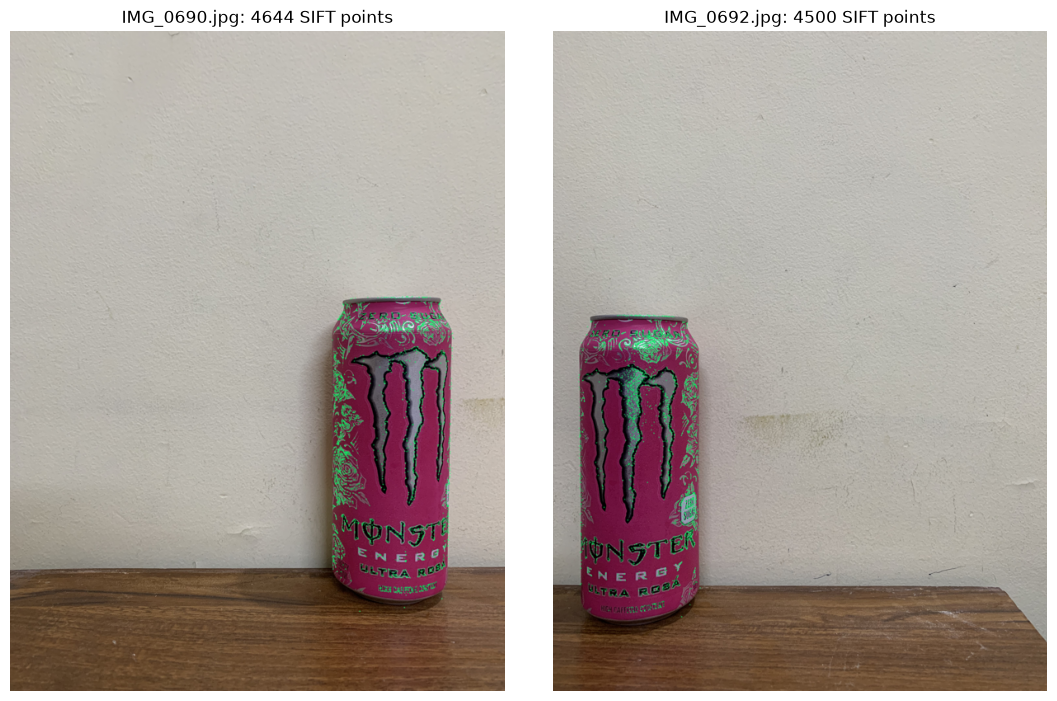

In [8]:

sift = cv2.SIFT_create(nfeatures=5000)

keypoints, descriptors = [], []
fig, axes = plt.subplots(1,2,figsize=(11,7))
for ax, rgb, mask, name in zip(axes, images, masks, FILES):
    kp, desc = sift.detectAndCompute(cv2.cvtColor(rgb, cv2.COLOR_RGB2GRAY), mask)
    if desc is None or len(kp) < 8: raise ValueError('Too few features in ' + name)
    keypoints.append(kp); descriptors.append(desc)
    view = cv2.drawKeypoints(rgb, kp, None, color=(0,255,100))
    ax.imshow(Image.fromarray(view).resize((600,800)))
    ax.set_title(f'{name}: {len(kp)} SIFT points'); ax.axis('off')
plt.tight_layout(); plt.savefig(RUN/'02_sift_points.png',dpi=130); plt.show()


## 4. Match descriptors and remove ambiguous matches
A brute force matcher compares descriptor vectors using Euclidean distance. For each point, the ratio test accepts its nearest match only if it is clearly better than the second nearest match: `distance1 < 0.70 × distance2`. A mutual check requires both matching directions to agree.

RANSAC then fits a fundamental matrix and marks geometrically inconsistent correspondences as outliers. Inliers support the fitted epipolar model; they do not prove correct calibration, parallel camera motion or accurate metric depth. The can occupies a limited region and can produce an ill-conditioned geometry estimate.


Features: 4644 4500
Forward ratio matches: 221 | Mutual: 127
RANSAC inliers: 81 | Rejected: 46


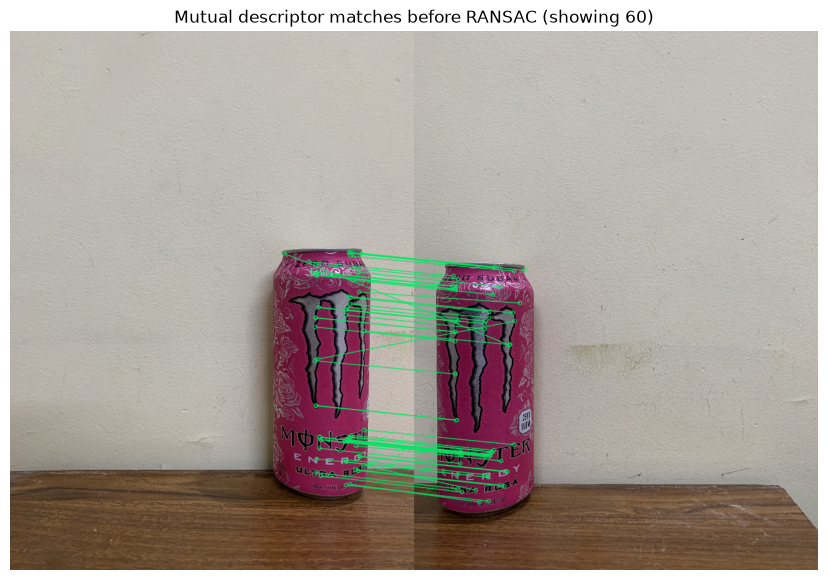

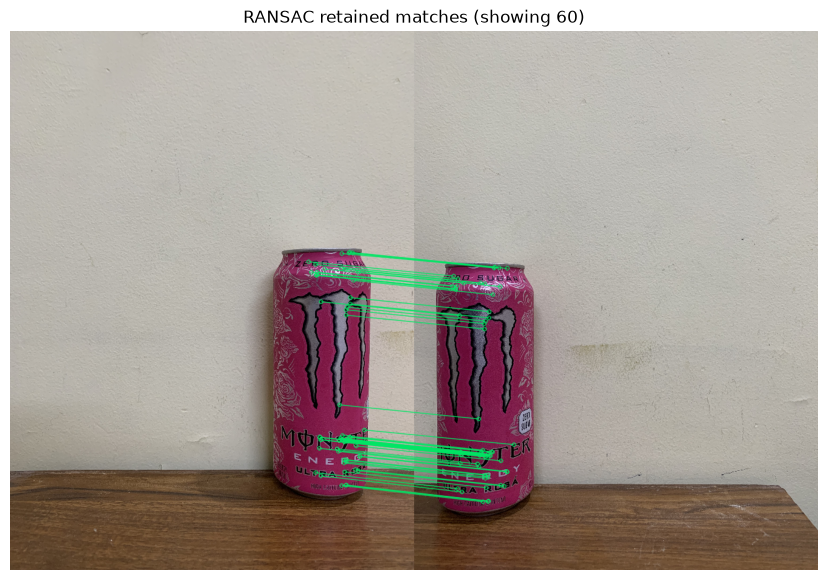

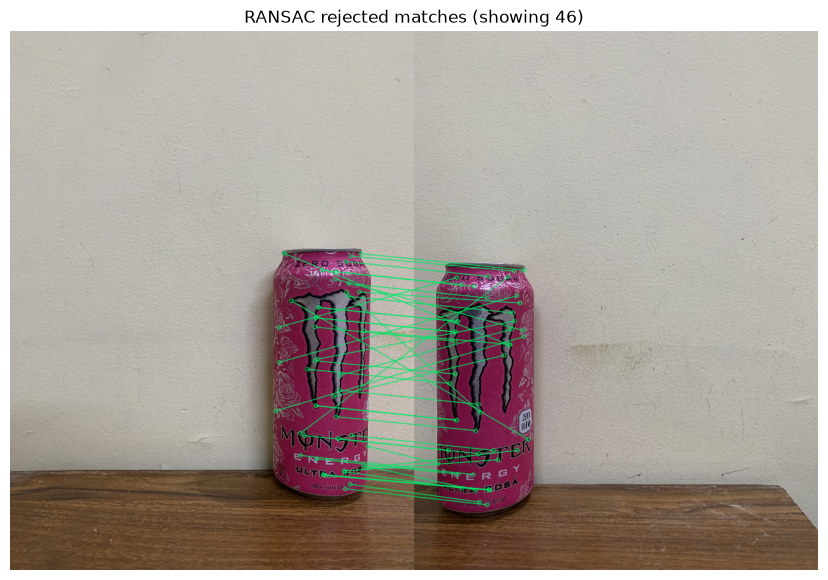

In [ ]:
matcher = cv2.BFMatcher(cv2.NORM_L2)
def ratio_matches(a,b):
    candidates = matcher.knnMatch(a,b,k=2)
    return [pair[0] for pair in candidates if len(pair)==2 and pair[0].distance < RATIO*pair[1].distance]
forward = ratio_matches(descriptors[0], descriptors[1])
reverse = ratio_matches(descriptors[1], descriptors[0])
reverse_pairs = {(m.trainIdx,m.queryIdx) for m in reverse}
mutual = [m for m in forward if (m.queryIdx,m.trainIdx) in reverse_pairs]
if len(mutual)<8: raise ValueError('Too few mutual correspondences')
left = np.float64([keypoints[0][m.queryIdx].pt for m in mutual])
right = np.float64([keypoints[1][m.trainIdx].pt for m in mutual])


F, inlier_mask = cv2.findFundamentalMat(left,right,cv2.FM_RANSAC,RANSAC_PX,0.999,10000)


if F is None or F.shape!=(3,3) or inlier_mask is None: raise ValueError('Fundamental matrix estimation failed')
inliers = inlier_mask.ravel().astype(bool)
if inliers.sum()<8: raise ValueError('Too few geometric inliers')
print('Features:',*[len(k) for k in keypoints])
print('Forward ratio matches:',len(forward),'| Mutual:',len(mutual))
print('RANSAC inliers:',int(inliers.sum()),'| Rejected:',int((~inliers).sum()))
def show_matches(selected,title,filename):
    # Reduce display images and keypoint coordinates only, never calculation coordinates.
    scale=0.22
    small=[cv2.resize(rgb,None,fx=scale,fy=scale) for rgb in images]
    small_kp=[[cv2.KeyPoint(k.pt[0]*scale,k.pt[1]*scale,max(k.size*scale,1)) for k in ks] for ks in keypoints]
    chosen=selected[:60]
    canvas=cv2.drawMatches(small[0],small_kp[0],small[1],small_kp[1],chosen,None,
                           matchColor=(0,230,100),flags=cv2.DrawMatchesFlags_NOT_DRAW_SINGLE_POINTS)
    Image.fromarray(canvas).save(RUN/filename)
    plt.figure(figsize=(12,7)); plt.imshow(canvas); plt.title(title + f' (showing {len(chosen)})'); plt.axis('off'); plt.show()
show_matches(mutual,'Mutual descriptor matches before RANSAC','03_mutual_matches.png')
show_matches([m for m,ok in zip(mutual,inliers) if ok],'RANSAC retained matches','04_inliers.png')
show_matches([m for m,ok in zip(mutual,inliers) if not ok],'RANSAC rejected matches','05_rejected.png')


## 5. Disparity and alignment: does simple stereo geometry apply?
For a parallel, distortion corrected pair, the same physical point should lie on the same image row. Horizontal disparity is `d = u_left − u_right`. Positive disparity is expected for the presumed image order. Vertical mismatch is `v_left − v_right`.

We report all RANSAC inliers and use an initial 2 pixel vertical mismatch criterion. This is a diagnostic threshold, not an accuracy guarantee. **We do not make the images artificially align and then use the original focal length:** arbitrary image warping changes the geometry.


Median signed horizontal disparity: 1970.87 px
Median absolute vertical mismatch: 111.14 px
90th percentile absolute vertical mismatch: 119.25 px
Within 2 px vertically: 0/81
Simple parallel-pair quality check: FAIL


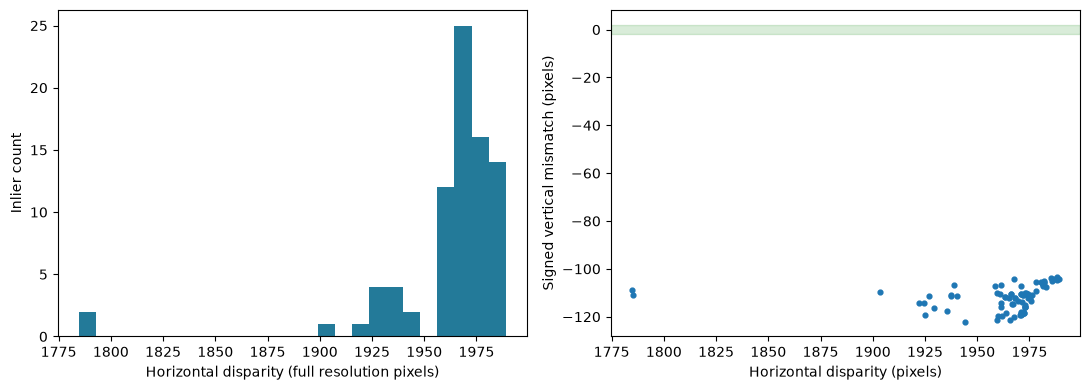

In [10]:
pL,pR = left[inliers],right[inliers]
disparity = pL[:,0]-pR[:,0]
vertical = pL[:,1]-pR[:,1]
positive = disparity > 10
aligned = np.abs(vertical)<=VERTICAL_LIMIT_PX
simple_geometry_pass = bool(np.all(positive & aligned))
median_d=float(np.median(disparity))
print(f'Median signed horizontal disparity: {median_d:.2f} px')
print(f'Median absolute vertical mismatch: {np.median(np.abs(vertical)):.2f} px')
print(f'90th percentile absolute vertical mismatch: {np.percentile(np.abs(vertical),90):.2f} px')
print(f'Within 2 px vertically: {aligned.sum()}/{len(aligned)}')
print('Simple parallel-pair quality check:', 'PASS' if simple_geometry_pass else 'FAIL')
fig,axes=plt.subplots(1,2,figsize=(11,4))
axes[0].hist(disparity,bins=25,color='#237a99'); axes[0].set_xlabel('Horizontal disparity (full resolution pixels)'); axes[0].set_ylabel('Inlier count')
axes[1].scatter(disparity,vertical,s=12); axes[1].axhspan(-2,2,color='green',alpha=.15)
axes[1].set_xlabel('Horizontal disparity (pixels)'); axes[1].set_ylabel('Signed vertical mismatch (pixels)')
plt.tight_layout(); plt.savefig(RUN/'06_alignment.png',dpi=150); plt.show()


## 6. Conditional depth estimate
The pinhole equation for a **parallel stereo pair** is:

$$Z=\frac{f_x B}{d}.$$

`B` is in metres; `f_x` and `d` are in pixels. EXIF reports a 26 mm **35 mm equivalent** focal length. It is not a calibrated focal length and must not be directly inserted as pixels. Assuming an uncropped image, square pixels and diagonal field of view equivalence, approximate:

$$f_x \approx \frac{f_{35}}{\sqrt{36^2+24^2}}\sqrt{W^2+H^2}.$$

The 36 × 24 mm values are the dimensions of a 35 mm-format sensor; the pixel diagonal converts that approximate field of view into pixels.

$$f_x \approx \frac{f_{35}}{\sqrt{36^2+24^2}}\sqrt{3024^2+4032^2}.$$


We apply this to the median disparity of the matched can surface points. The result describes a typical visible surface depth under the model. It is not the can centre, and it is not a verified straight line lens-to-object distance. Failed alignment, unmodelled rotation, distortion and baseline uncertainty can bias it. No ground truth from an earlier capture is reused.


In [ ]:
f35=metadata[0]['equivalent_focal_mm']
if f35<=0 or f35!=metadata[1]['equivalent_focal_mm']: raise ValueError('Missing or different equivalent focal lengths')
focal_px=f35/np.hypot(36,24)*np.hypot(w,h)
if median_d<=10: raise ValueError('Non-positive or insufficient median disparity; inspect image order')
conditional_depth_m=float(focal_px*BASELINE_M/median_d)
print(f'Approximate focal length: {focal_px:.2f} pixels')
print(f'Assumed baseline: {BASELINE_M*100:.1f} cm')
print(f'Conditional depth = {focal_px:.2f} × {BASELINE_M:.3f} / {median_d:.2f}')
print(f'CONDITIONAL DEPTH: {conditional_depth_m*100:.1f} cm')
print('Validated metric distance: NOT AVAILABLE (no calibration / verified camera pose).')
if not simple_geometry_pass:
    display(Markdown('**Alignment check failed: this numeric result must not be presented as an accurate measured distance.**'))
if GROUND_TRUTH_M is not None:
    assert np.isfinite(GROUND_TRUTH_M) and GROUND_TRUTH_M>0
    print('Conditional estimate absolute error (cm):',abs(conditional_depth_m-GROUND_TRUTH_M)*100)
    print('Conditional estimate percentage error:',abs(conditional_depth_m-GROUND_TRUTH_M)/GROUND_TRUTH_M*100)
print('Baseline sensitivity with the same disparity (assumptions, not confidence bounds):')


Approximate focal length: 3028.66 pixels
Assumed baseline: 20.1 cm
Conditional depth = 3028.66 × 0.201 / 1970.87
CONDITIONAL DEPTH: 30.9 cm
Validated metric distance: NOT AVAILABLE (no calibration / verified camera pose).


**Alignment check failed: this numeric result must not be presented as an accurate measured distance.**

Conditional estimate absolute error (cm): 2.8879904127519174
Conditional estimate percentage error: 10.31425147411399
Baseline sensitivity with the same disparity (assumptions, not confidence bounds):


## 7. Save evidence and reproducibility
Save image hashes, EXIF focal metadata, exact configuration, software versions, fundamental matrix, matching counts, correspondence coordinates and quality verdict. The CSV includes every mutual match, its RANSAC classification and raw displacement. The original images are preserved.


In [12]:
summary=dict(inputs=metadata, upright_size_px=[w,h], baseline_m=BASELINE_M,
 baseline_status='student estimate, approximately 20.1 cm', focal_px_approx=float(focal_px),
 focal_method='35mm equivalent diagonal approximation, not calibration',
 keypoint_counts=[len(k) for k in keypoints], forward_ratio_count=len(forward), mutual_count=len(mutual),
 ransac_inliers=int(inliers.sum()), ransac_rejected=int((~inliers).sum()),
 ratio_threshold=RATIO,ransac_threshold_px=RANSAC_PX,vertical_threshold_px=VERTICAL_LIMIT_PX,
 roi_normalized=ROIS, median_disparity_px=median_d,
 median_abs_vertical_px=float(np.median(np.abs(vertical))),
 p90_abs_vertical_px=float(np.percentile(np.abs(vertical),90)),
 vertical_accepted=int(aligned.sum()), simple_geometry_pass=simple_geometry_pass,
 conditional_depth_m=conditional_depth_m,validated_distance_m=None,ground_truth_m=GROUND_TRUTH_M,
 fundamental_matrix=F.tolist(),
 versions=dict(python=platform.python_version(),opencv=cv2.__version__,numpy=np.__version__),
 limitations=['uncalibrated intrinsics and lens distortion','unverified motion and baseline',
              'raw unrectified disparities','restricted object support for fundamental matrix',
              'typical matched surface depth, not object centre range'])
(RUN/'summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
with (RUN/'correspondences.csv').open('w',newline='',encoding='utf-8') as stream:
    writer=csv.writer(stream);writer.writerow(['u_left','v_left','u_right','v_right','disparity_px','vertical_px','ransac_inlier'])
    for a,b,ok in zip(left,right,inliers): writer.writerow([*a,*b,a[0]-b[0],a[1]-b[1],bool(ok)])
print('Evidence saved:',RUN)


Evidence saved: d:\Bunker\BaseCamp\ComputerVision\StereoviSON and Depth EstimaSON\results\refined_20261022_104214_758056


## 8. Local patch refinement and forward/backward consistency

SIFT finds approximate corresponding feature positions. We use **pyramidal Lucas–Kanade** to adjust the right position until local image intensities agree more closely with the left patch. SIFT initializes the large displacement (about 1970 pixels); LK is used only as a local refinement.

Parameters fixed before looking at the new error: 31×31 patch, pyramid levels 0–2, up to 50 iterations, 0.001 pixel stopping tolerance. The left point is fixed; the right point is refined. A backward track returns from the refined right point to the left photo, initialized at its original left location.

Accept only successful tracks with **forward/backward residual ≤1 pixel**, **right-point correction ≤8 pixels**, and patch centres inside the image. The correction limit prevents large local drift. Forward/backward agreement can still accept a repeated-pattern false match; it is a filter, not proof of correspondence correctness. Brightness changes, glare and viewpoint changes may violate LK assumptions.

The earlier fundamental-matrix fit belongs only to the baseline. Refinement starts from all mutual SIFT matches; after filtering, a new essential-matrix RANSAC rejects geometric outliers.


def refine_matches(gray_left, gray_right, left, right, fb_limit_px=1.0,
                   correction_limit_px=8.0):
    a = np.asarray(left, np.float32).reshape(-1, 1, 2)
    b = np.asarray(right, np.float32).reshape(-1, 1, 2)
    if len(a) != len(b) or len(a) == 0:
        raise ValueError("Nonempty paired starting points are required")
    if gray_left.shape != gray_right.shape or gray_left.ndim != 2:
        raise ValueError("Grayscale image dimensions must agree")
    if not np.isfinite(a).all() or not np.isfinite(b).all():
        raise ValueError("Coordinates must be finite")
    if fb_limit_px <= 0 or correction_limit_px <= 0:
        raise ValueError("Thresholds must be positive")
    settings = dict(winSize=(31, 31), maxLevel=2,
                    criteria=(cv2.TERM_CRITERIA_EPS | cv2.TERM_CRITERIA_COUNT, 50, .001),
                    flags=cv2.OPTFLOW_USE_INITIAL_FLOW, minEigThreshold=1e-4)
    # SIFT provides the large displacement. LK only refines its local neighbourhood

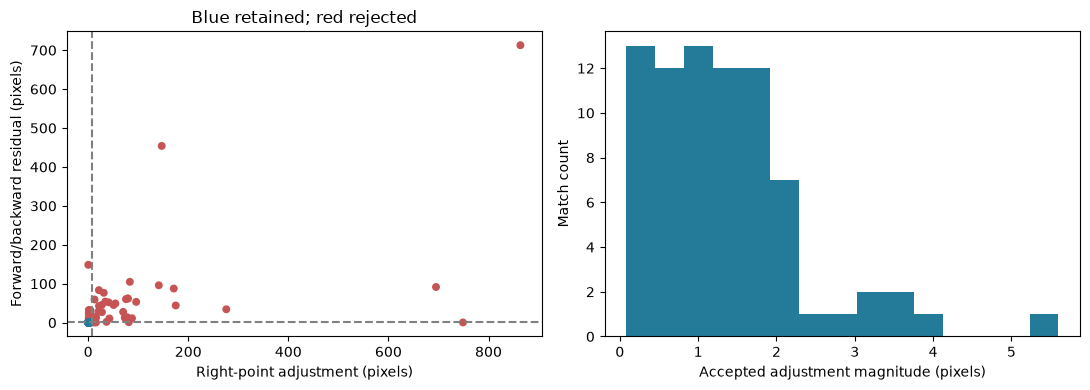

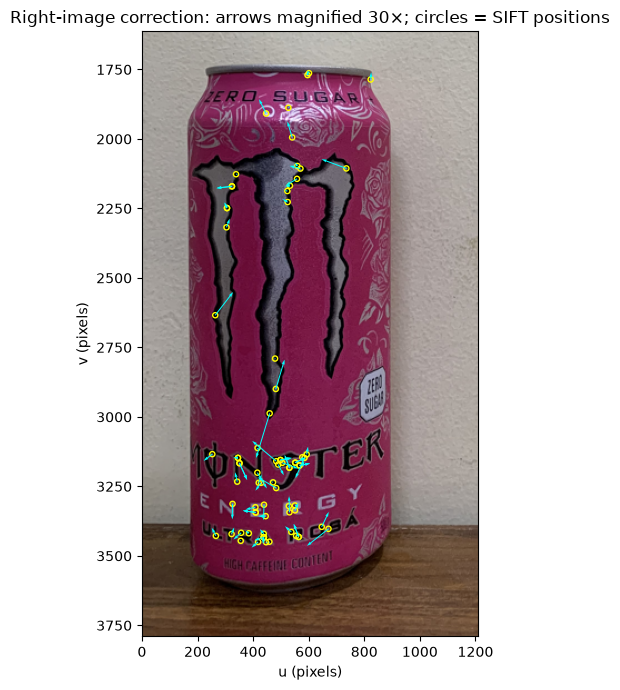

In [13]:
import inspect
from src.refinement import refine_matches
from src.pose import reconstruct
print(inspect.getsource(refine_matches))
FB_LIMIT_PX=1.0
CORRECTION_LIMIT_PX=8.0
refined=refine_matches(cv2.cvtColor(images[0],cv2.COLOR_RGB2GRAY),
                       cv2.cvtColor(images[1],cv2.COLOR_RGB2GRAY),left,right,
                       fb_limit_px=FB_LIMIT_PX,correction_limit_px=CORRECTION_LIMIT_PX)
keep=refined['keep']
print('Mutual SIFT candidates:',len(left))
print('Accepted after local refinement and consistency:',int(keep.sum()))
print('Rejected:',int((~keep).sum()))
if keep.any():
    print('Median right-point adjustment (px):',np.median(refined['correction_px'][keep]))
    print('Median forward/backward residual (px):',np.median(refined['forward_backward_px'][keep]))
fig,axes=plt.subplots(1,2,figsize=(11,4))
finite=np.isfinite(refined['forward_backward_px'])&np.isfinite(refined['correction_px'])
axes[0].scatter(refined['correction_px'][finite],refined['forward_backward_px'][finite],
                c=np.where(keep[finite],'#237a99','#c65454'),s=22)
axes[0].axvline(CORRECTION_LIMIT_PX,color='gray',ls='--');axes[0].axhline(FB_LIMIT_PX,color='gray',ls='--')
axes[0].set_xlabel('Right-point adjustment (pixels)');axes[0].set_ylabel('Forward/backward residual (pixels)')
axes[0].set_title('Blue retained; red rejected')
axes[1].hist(refined['correction_px'][keep],bins=15,color='#237a99')
axes[1].set_xlabel('Accepted adjustment magnitude (pixels)');axes[1].set_ylabel('Match count')
plt.tight_layout();plt.savefig(RUN/'07_refinement_checks.png',dpi=150);plt.show()
# Same image positions before/after, with displacement magnified only for visibility.
fig,ax=plt.subplots(figsize=(7,7))
ax.imshow(Image.fromarray(images[1]).resize((756,1008)),extent=(0,w,h,0))
old=right[keep]; delta=refined['right'][keep]-old
ax.scatter(old[:,0],old[:,1],s=14,facecolors='none',edgecolors='yellow')
ax.quiver(old[:,0],old[:,1],delta[:,0]*30,delta[:,1]*30,
          angles='xy',scale_units='xy',scale=1,color='cyan',width=.003)
ax.set_title('Right-image correction: arrows magnified 30×; circles = SIFT positions')
ax.set_xlim(0,w*.4);ax.set_ylim(h*.94,h*.40);ax.set_xlabel('u (pixels)');ax.set_ylabel('v (pixels)')
plt.tight_layout();plt.savefig(RUN/'08_patch_adjustments.png',dpi=150);plt.show()


## 9. Triangulate the filtered, refined correspondences

Essential-matrix RANSAC estimates relative camera motion from approximate calibrated rays. Pose recovery selects a rotation and translation direction using positive depth. Translation is scaled to **0.201 m full Euclidean lens separation**. Projection matrices $P_L=K[I|0]$ and $P_R=K[R|t]$ triangulate the 3D points. No ground truth is used to estimate motion or scale.

The result is median **Z depth of the matched visible surface**, not can-centre range. A curved can and uncertain measurement reference limit comparison with a single measured front-surface distance.

Screening thresholds: ≥20 positive-depth points, ≥70% of essential inliers in front of both cameras, P90 reprojection error ≤3 px, median parallax ≥1°. Twenty seeded 80% subset fits additionally require ≥16 successes, P90–P10 depth spread ≤20% of the full estimate, and P90 relative rotation change ≤3°. These are exploratory stability checks, not accuracy certification.


In [14]:
K=np.array([[focal_px,0,(w-1)/2],[0,focal_px,(h-1)/2],[0,0,1]],float)
pose=None
failure=None
checks={}
subset_rows=[]
if keep.sum()<8:
    failure='Fewer than eight refined matches survived'
else:
    try:
        pose=reconstruct(refined['left'][keep],refined['right'][keep],K,BASELINE_M)
    except ValueError as exc:
        failure=str(exc)
if pose is not None:
    a,b=refined['left'][keep],refined['right'][keep]
    rng=np.random.default_rng(2026)
    for seed in range(20):
        idx=rng.choice(len(a),max(8,int(.8*len(a))),replace=False)
        try:
            fit=reconstruct(a[idx],b[idx],K,BASELINE_M,seed=seed)
            delta=fit['R']@pose['R'].T
            angle=float(np.degrees(np.arccos(np.clip((np.trace(delta)-1)/2,-1,1))))
            subset_rows.append(dict(success=True,seed=seed,depth_m=fit['median_depth_m'],rotation_difference_deg=angle))
        except ValueError as exc:
            subset_rows.append(dict(success=False,seed=seed,error=str(exc)))
    good=[r for r in subset_rows if r['success']]
    spread=float((np.percentile([r['depth_m'] for r in good],90)-np.percentile([r['depth_m'] for r in good],10))/pose['median_depth_m']) if good else float('inf')
    rot90=float(np.percentile([r['rotation_difference_deg'] for r in good],90)) if good else float('inf')
    checks=dict(positive_points=pose['positive_count']>=20,positive_fraction=pose['cheirality_fraction']>=.70,
                reprojection=np.percentile(pose['reprojection_px'],90)<=3,
                parallax=np.median(pose['parallax_deg'])>=1,subset_success=len(good)>=16,
                subset_depth_spread=spread<=.20,subset_rotation=rot90<=3)
    print('Essential inliers / positive-depth points:',pose['essential_count'],pose['positive_count'])
    print('Recovered rotation (deg):',pose['rotation_deg'])
    print('P90 reprojection error (px):',np.percentile(pose['reprojection_px'],90))
    print('Median parallax angle (deg):',np.median(pose['parallax_deg']))
    print('Subset successes:',len(good),'/20 | Relative depth spread:',spread,'| P90 rotation change (deg):',rot90)
    print('Median surface depth (cm):',pose['median_depth_m']*100)
    print('Median surface Euclidean range (cm):',pose['median_range_m']*100)
else:
    print('TRIANGULATION REJECTED:',failure)
screen_pass=bool(checks and all(checks.values()))
print('Screening:',{k:bool(v) for k,v in checks.items()})
print('Verdict:', 'Screen passed; still uncalibrated' if screen_pass else 'Screen failed / exploratory only')


Essential inliers / positive-depth points: 60 60
Recovered rotation (deg): 3.7393772708192086
P90 reprojection error (px): 0.7902849158728928
Median parallax angle (deg): 35.249152280569874
Subset successes: 20 /20 | Relative depth spread: 0.21601888818141662 | P90 rotation change (deg): 5.522589463172954
Median surface depth (cm): 29.809245961405082
Median surface Euclidean range (cm): 33.057477117796566
Screening: {'positive_points': True, 'positive_fraction': True, 'reprojection': True, 'parallax': True, 'subset_success': True, 'subset_depth_spread': False, 'subset_rotation': False}
Verdict: Screen failed / exploratory only


## 10. Compare with the measured 28 cm depth

Compare the original raw-disparity baseline and the new full pipeline. A diagnostic raw-disparity estimate on exactly the final retained correspondences separates point selection from coordinate adjustment. No parameters are chosen to force agreement with 28 cm.


Same final matches: original / refined median disparity (px): 1971.999984741211 1972.2613220214844
{'method': 'Original raw disparity', 'depth_cm': 30.88799041275192, 'absolute_error_cm': 2.8879904127519174, 'percentage_error': 10.31425147411399, 'status': 'Vertical check failed'}
{'method': 'Raw disparity on final selected matches', 'depth_cm': 30.87024756895365, 'absolute_error_cm': 2.8702475689536486, 'percentage_error': 10.250884174834459, 'status': 'Selection diagnostic only'}
{'method': 'Refinement + consistency + triangulation', 'depth_cm': 29.809245961405082, 'absolute_error_cm': 1.8092459614050815, 'percentage_error': 6.461592719303861, 'status': 'Screen failed / exploratory'}


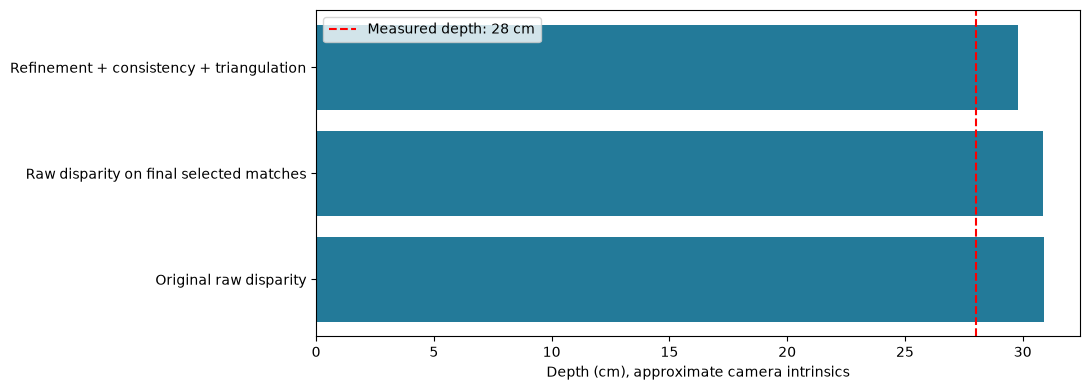

**Actual result:** error changed from 10.31% to 6.46% (+3.85 percentage points of reduction). This single capture does not establish general improvement.

Saved all evidence: d:\Bunker\BaseCamp\ComputerVision\StereoviSON and Depth EstimaSON\results\refined_20261022_104214_758056


In [15]:
comparison=[]
def add_row(method,depth,status):
    comparison.append(dict(method=method,depth_cm=float(depth*100),
        absolute_error_cm=float(abs(depth-GROUND_TRUTH_M)*100),
        percentage_error=float(abs(depth-GROUND_TRUTH_M)/GROUND_TRUTH_M*100),status=status))
add_row('Original raw disparity',conditional_depth_m,'Vertical check failed')
if pose is not None:
    original_indices=np.flatnonzero(keep)[pose['indices']]
    selected_d=float(np.median(left[original_indices,0]-right[original_indices,0]))
    refined_d=float(np.median(refined['left'][original_indices,0]-refined['right'][original_indices,0]))
    print('Same final matches: original / refined median disparity (px):',selected_d,refined_d)
    if selected_d>10:add_row('Raw disparity on final selected matches',focal_px*BASELINE_M/selected_d,'Selection diagnostic only')
    add_row('Refinement + consistency + triangulation',pose['median_depth_m'],
            'Screen passed, uncalibrated' if screen_pass else 'Screen failed / exploratory')
for row in comparison:print(row)
fig,ax=plt.subplots(figsize=(11,4))
ax.barh([r['method'] for r in comparison],[r['depth_cm'] for r in comparison],color='#237a99')
ax.axvline(28,color='red',ls='--',label='Measured depth: 28 cm');ax.legend()
ax.set_xlabel('Depth (cm), approximate camera intrinsics')
plt.tight_layout();plt.savefig(RUN/'09_refined_comparison.png',dpi=150);plt.show()
if pose is not None:
    improvement=comparison[0]['percentage_error']-comparison[-1]['percentage_error']
    display(Markdown(f'**Actual result:** error changed from {comparison[0]["percentage_error"]:.2f}% to {comparison[-1]["percentage_error"]:.2f}% ({improvement:+.2f} percentage points of reduction). This single capture does not establish general improvement.'))
with (RUN/'refined_correspondences.csv').open('w',newline='',encoding='utf-8') as stream:
    writer=csv.writer(stream);writer.writerow(['uL','vL','uR_sift','vR_sift','uR_refined','vR_refined','fb_px','correction_px','accepted'])
    for i in range(len(left)):
        writer.writerow([*left[i],*right[i],*refined['right'][i],refined['forward_backward_px'][i],refined['correction_px'][i],bool(keep[i])])
report=dict(pipeline='SIFT -> local LK refinement -> forward/backward check -> essential RANSAC -> triangulation',
            baseline_m=BASELINE_M,ground_truth_depth_m=GROUND_TRUTH_M,
            input_count=len(left),accepted_refinement=int(keep.sum()),
            fb_limit_px=FB_LIMIT_PX,correction_limit_px=CORRECTION_LIMIT_PX,
            comparison=comparison,screening={k:bool(v) for k,v in checks.items()},screen_pass=screen_pass,
            failure=failure,subsets=subset_rows,camera_matrix_approx=K.tolist(),validated_distance_m=None,
            source_hashes={f:hashlib.sha256((PROJECT/'src'/f).read_bytes()).hexdigest() for f in ['pose.py','refinement.py']})
if pose is not None:
    report.update(rotation_deg=pose['rotation_deg'],median_depth_m=pose['median_depth_m'],
                  positive_points=pose['positive_count'],essential_inliers=pose['essential_count'])
    np.savez(RUN/'refined_triangulation.npz',R=pose['R'],translation_m=pose['translation_m'],
             xyz_m=pose['xyz_m'],mutual_match_indices=original_indices,
             reprojection_px=pose['reprojection_px'],parallax_deg=pose['parallax_deg'])
(RUN/'refinement_summary.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
print('Saved all evidence:',RUN)


## 11. Interpretation and next experiment

Patch refinement may improve coordinate precision and reject inconsistent matches. It cannot by itself correct an inaccurate baseline, focal length, principal point or lens distortion. Consistent repeated-pattern matches may remain incorrect. A low reprojection residual and a passed screening check do not validate centimetre accuracy.

Evaluate this proposed improvement using independent repeated captures at measured distances. Keep calibration and tuning separate from final evaluation. Report rejected pairs and error as well as matching counts. Do not choose parameters on the basis of this one 28 cm measurement.

References: [OpenCV Lucas–Kanade and forward/backward tracking](https://docs.opencv.org/4.x/d4/dee/tutorial_optical_flow.html), [camera geometry and triangulation](https://docs.opencv.org/4.x/d9/d0c/group__calib3d.html), [SIFT](https://docs.opencv.org/4.x/da/df5/tutorial_py_sift_intro.html).


## Executed outcome

| Method | Surface depth | Error against 28 cm |
|---|---:|---:|
| Original raw disparity | 30.89 cm | 10.31% |
| SIFT + local refinement + consistency + triangulation | 29.81 cm | 6.46% |

**On this capture, the new estimate is closer by 1.08 cm, a 3.85 percentage point reduction in error.** Of 127 mutual candidates, 77 passed local checks and 60 passed essential-matrix and positive-depth checks. Median right-point adjustment was 1.23 px; median forward/backward residual was 0.19 px.

**The estimate fails stability screening:** subset P90–P10 relative depth spread is 21.60%, exceeding the declared 20% threshold, and P90 relative rotation change is 5.52°, exceeding 3°. P90 reprojection error is only 0.79 px, illustrating why small image residuals alone do not establish metric accuracy.

On the final selected matches the original/refined median disparities are 1972.00/1972.26 px. Thus the centimetre-scale output change cannot be attributed to subpixel disparity correction alone; filtering and re-estimated pose also change. This combined pipeline comparison does not isolate which component caused the change. A repeated evaluation and controlled component ablations would be needed to claim reliable improvement.

**Implementation check:** local refinement on a synthetic known subpixel translation retained 20/24 points and obtained median coordinate error 0.014 px. The triangulation module was separately checked against known nonparallel synthetic geometry. These ideal checks do not validate phone measurement accuracy.
